# Exploratory Data Analysis (EDA) and Data Visualization on Student Academic Performance

**Original Dataset:** [Student Performance Factors (Kaggle)](https://www.kaggle.com/datasets/lainguyn123/student-performance-factors)  
**Direct CSV URL (Colab-ready):** `https://raw.githubusercontent.com/fiaaha/StudentPerformanceFactors/main/StudentPerformanceFactors.csv`

In [1]:
# Step 1: Import Required Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
# Step 2: Load the Real Dataset into Google Colab
DATASET_URL = (
    "https://raw.githubusercontent.com/fiaaha/"
    "StudentPerformanceFactors/main/StudentPerformanceFactors.csv"
)
df = pd.read_csv(DATASET_URL)
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
# Step 3: Display Dataset Shape, Columns, Data Types, and First 5 Rows
print(f"Dataset Shape: {df.shape[0]} rows x {df.shape[1]} columns")
print("\nColumns:", df.columns.tolist())
print("\nData Types:\n", df.dtypes)
df[["Hours_Studied", "Attendance", "Previous_Scores", "Exam_Score"]].head()

Dataset Shape: 6607 rows x 20 columns

Columns: ['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']

Data Types:
 Hours_Studied                 int64
Attendance                    int64
Parental_Involvement            str
Access_to_Resources             str
Extracurricular_Activities      str
Sleep_Hours                   int64
Previous_Scores               int64
Motivation_Level                str
Internet_Access                 str
Tutoring_Sessions             int64
Family_Income                   str
Teacher_Quality                 str
School_Type                     str
Peer_Influence                  str
Physical_Activity             int64
Learni

,Hours_Studied,Attendance,Previous_Scores,Exam_Score
0,23,84,73,67
1,19,64,59,61
2,24,98,91,74
3,29,89,98,71
4,19,92,65,70


In [4]:
# Step 4: Basic Data Cleaning and Handling Missing Values
print("Missing Values Before Cleaning:")
missing_before = df.isnull().sum()
print(missing_before[missing_before > 0])
print(f"\nDuplicate Rows: {df.duplicated().sum()}")

df_clean = df.copy()
for col in df_clean.columns:
    if df_clean[col].isnull().sum() > 0:
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print(f"Total Missing Values After Cleaning: {df_clean.isnull().sum().sum()}")
print(f"Records with Exam_Score > 100: {len(df_clean[df_clean['Exam_Score'] > 100])}")

Missing Values Before Cleaning:
Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64

Duplicate Rows: 0
Total Missing Values After Cleaning: 0
Records with Exam_Score > 100: 1


In [5]:
# Step 5 & 6: Select Relevant Numerical Columns and Compute Descriptive Statistics
selected_cols = ["Hours_Studied", "Attendance", "Previous_Scores", "Exam_Score"]
eda_df = df_clean[selected_cols]

stats_summary = pd.DataFrame({
    "Mean": eda_df.mean(),
    "Median": eda_df.median(),
    "Mode": eda_df.mode().iloc[0],
    "Variance": eda_df.var(),
    "Std_Dev": eda_df.std(),
    "Min": eda_df.min(),
    "Max": eda_df.max(),
})
stats_summary.round(2)

,Mean,Median,Mode,Variance,Std_Dev,Min,Max
Hours_Studied,19.98,20.0,20,35.89,5.99,1,44
Attendance,79.98,80.0,67,133.34,11.55,60,100
Previous_Scores,75.07,75.0,66,207.35,14.40,50,100
Exam_Score,67.24,67.0,68,15.14,3.89,55,101


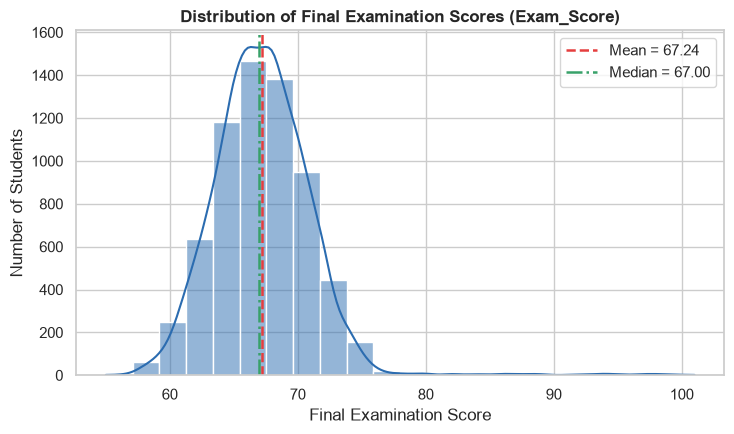

In [6]:
# Step 7: Histogram of Final Examination Scores
plt.figure(figsize=(7.5, 4.5))
sns.histplot(eda_df["Exam_Score"], bins=22, kde=True, color="#2B6CB0", edgecolor="white")
mean_score = eda_df["Exam_Score"].mean()
median_score = eda_df["Exam_Score"].median()
plt.axvline(mean_score, color="#E53E3E", linestyle="--", linewidth=1.8, label=f"Mean = {mean_score:.2f}")
plt.axvline(median_score, color="#38A169", linestyle="-.", linewidth=1.8, label=f"Median = {median_score:.2f}")
plt.title("Distribution of Final Examination Scores (Exam_Score)", fontsize=12, fontweight="bold")
plt.xlabel("Final Examination Score")
plt.ylabel("Number of Students")
plt.legend()
plt.tight_layout()
plt.show()

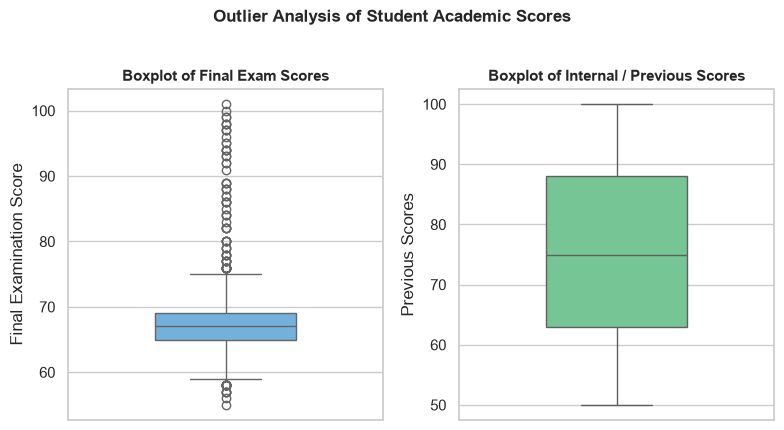

In [7]:
# Step 8: Boxplot to Identify Possible Outliers in Student Scores
fig, axes = plt.subplots(1, 2, figsize=(8.0, 4.2))
sns.boxplot(y=eda_df["Exam_Score"], ax=axes[0], color="#63B3ED", width=0.45)
axes[0].set_title("Boxplot of Final Exam Scores", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Final Examination Score")

sns.boxplot(y=eda_df["Previous_Scores"], ax=axes[1], color="#68D391", width=0.45)
axes[1].set_title("Boxplot of Internal / Previous Scores", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Previous Scores")

plt.suptitle("Outlier Analysis of Student Academic Scores", fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

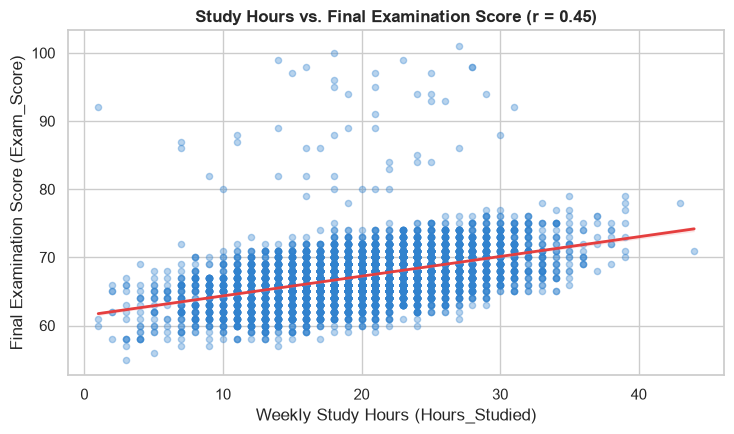

In [8]:
# Step 9: Scatter Plot - Study Hours vs. Final Examination Score
plt.figure(figsize=(7.5, 4.5))
sns.regplot(
    x="Hours_Studied", y="Exam_Score", data=eda_df,
    scatter_kws={"alpha": 0.35, "s": 20, "color": "#3182CE"},
    line_kws={"color": "#E53E3E", "linewidth": 2}
)
r_val = eda_df["Hours_Studied"].corr(eda_df["Exam_Score"])
plt.title(f"Study Hours vs. Final Examination Score (r = {r_val:.2f})", fontsize=12, fontweight="bold")
plt.xlabel("Weekly Study Hours (Hours_Studied)")
plt.ylabel("Final Examination Score (Exam_Score)")
plt.tight_layout()
plt.show()

Pearson Correlation Matrix:
                 Hours_Studied  Attendance  Previous_Scores  Exam_Score
Hours_Studied           1.0000     -0.0099           0.0248      0.4455
Attendance             -0.0099      1.0000          -0.0202      0.5811
Previous_Scores         0.0248     -0.0202           1.0000      0.1751
Exam_Score              0.4455      0.5811           0.1751      1.0000


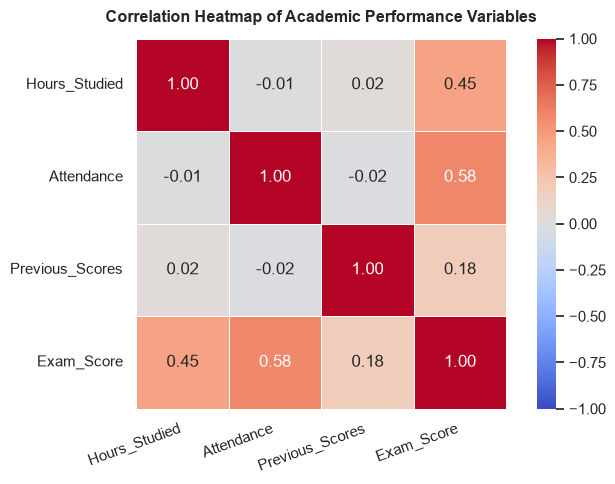

In [9]:
# Step 10 & 11: Correlation Matrix and Heatmap
corr_matrix = eda_df.corr()
print("Pearson Correlation Matrix:")
print(corr_matrix.round(4))

plt.figure(figsize=(7.2, 5.0))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.6, square=True)
plt.title("Correlation Heatmap of Academic Performance Variables", fontsize=11.5, fontweight="bold", pad=12)
plt.xticks(rotation=20, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()